# M6.8 · 监控/日志/容灾/灰度

> 上线后要持续采集指标、做健康检查与结构化日志，异常时能容灾恢复；
> 新版本用灰度逐步放量，出问题可快速回退。

## 一、机制

1. **指标监控**：计数器/仪表盘采集，对应 Prometheus + Grafana 告警；
2. **健康检查**：存活/就绪探针，依赖异常自动摘流；
3. **灰度发布**：按比例在稳定版与灰度版间分流，逐步放量；
4. **容灾备份**：定期备份并校验可恢复。

## 二、监控与灰度

In [1]:
import sys, random
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
from live_lab2 import monitor_ops as mo
metrics = mo.MetricsRegistry(); metrics.inc('orders', 5); metrics.gauge('nav', 1.02)
print('指标快照=%s' % metrics.snapshot())
hc = mo.HealthCheck(); hc.register('db', lambda: True); hc.register('wind', lambda: False)
print('健康检查=%s' % hc.check())
router = mo.CanaryRouter(0.0); router.rollout(0.5)
random.seed(1)
routes = [router.route(random) for _ in range(100)]
print('灰度50%% 实际 canary 占比=%.2f' % (routes.count('canary')/100))
bm = mo.BackupManager(); bm.backup('snap-1')
print('恢复存在备份=%s 恢复不存在=%s' % (bm.restore('snap-1')['ok'], bm.restore('x')['ok']))

指标快照={'orders': 5, 'nav': 1.02}
健康检查={'healthy': False, 'probes': {'db': True, 'wind': False}}
灰度50% 实际 canary 占比=0.47
恢复存在备份=True 恢复不存在=False


## 三、可视化：灰度放量

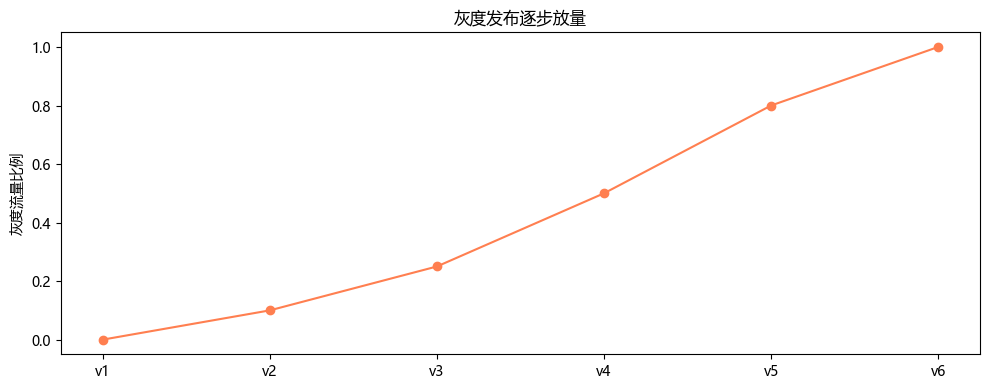

In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(10, 4))
steps = [0.0, 0.1, 0.25, 0.5, 0.8, 1.0]
ax.plot(range(len(steps)), steps, 'o-', color='coral')
ax.set_xticks(range(len(steps))); ax.set_xticklabels(['v1', 'v2', 'v3', 'v4', 'v5', 'v6'])
ax.set_ylabel('灰度流量比例'); ax.set_title('灰度发布逐步放量')
plt.tight_layout(); plt.show()

## 四、面试要点

- **监控要采集哪些指标？** 业务指标（订单/成交/净值）、系统指标（延迟/CPU/内存）、错误率与队列积压。
- **存活与就绪探针区别？** 存活判断进程是否卡死需重启，就绪判断是否能接收流量，未就绪则摘流但不重启。
- **灰度相比全量发布的优势？** 小流量先验证，异常影响面小，可快速回退，配合监控自动熔断。
- **容灾要验证什么？** 不仅定期备份，还要定期演练恢复，确认备份可用、RTO/RPO 达标。

## 五、练习

1. 给指标加阈值告警规则。
2. 实现灰度异常自动回退到 0%。
3. 设计结构化日志的统一字段。
4. 估算给定 RPO/RTO 下的备份频率。